In [1]:
print("hi")

hi


In [ ]:
!pip install git+https://github.com/mistralai/timestral.git


In [24]:
import numpy as np
from timestral import TimestralForecaster

forecaster = TimestralForecaster.from_pretrained("mistralai/Timestral-209M")  # device="cuda" for a GPU

context = np.random.randn(2, 1, 2000).cumsum(-1)        # (series, variates, time); NaN = missing
forecast = forecaster.forecast(context, prediction_length=1000)

forecast.quantiles.shape   # (2, 1, 96, 21): series, variates, horizon, quantile levels
forecast.quantile_levels   # (0.01, 0.05, 0.1, ..., 0.9, 0.95, 0.99)
forecast.median            # (2, 1, 96)
forecast.quantile(0.9)     # (2, 1, 96)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

tensor([[[ 54.3900,  54.9104,  55.3131,  ..., 108.5042, 108.2932, 110.0821]],

        [[  5.5622,   6.1156,   6.4906,  ...,  21.5354,  21.4777,  21.9006]]])

In [6]:
np.random.randn(2, 1, 2000).shape

(2, 1, 2000)

In [ ]:
 'median',
 'quantile',
 'quantile_levels',
 'quantiles'

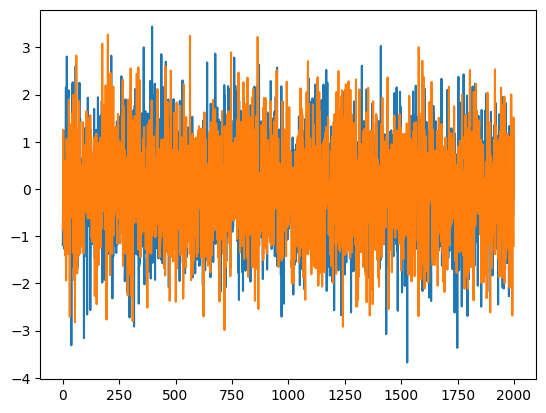

In [14]:
import matplotlib.pyplot as plt

def plot(x):
    plt.plot(x[:, 0].T)
    plt.show()

plot(np.random.randn(2, 1, 2000))

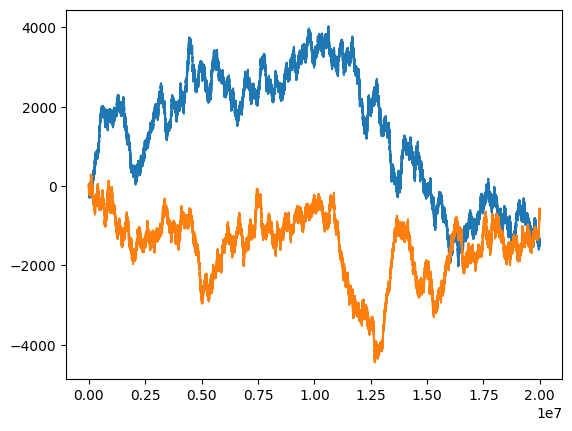

In [23]:
plot(np.random.randn(2, 1, 20000000).cumsum(-1))

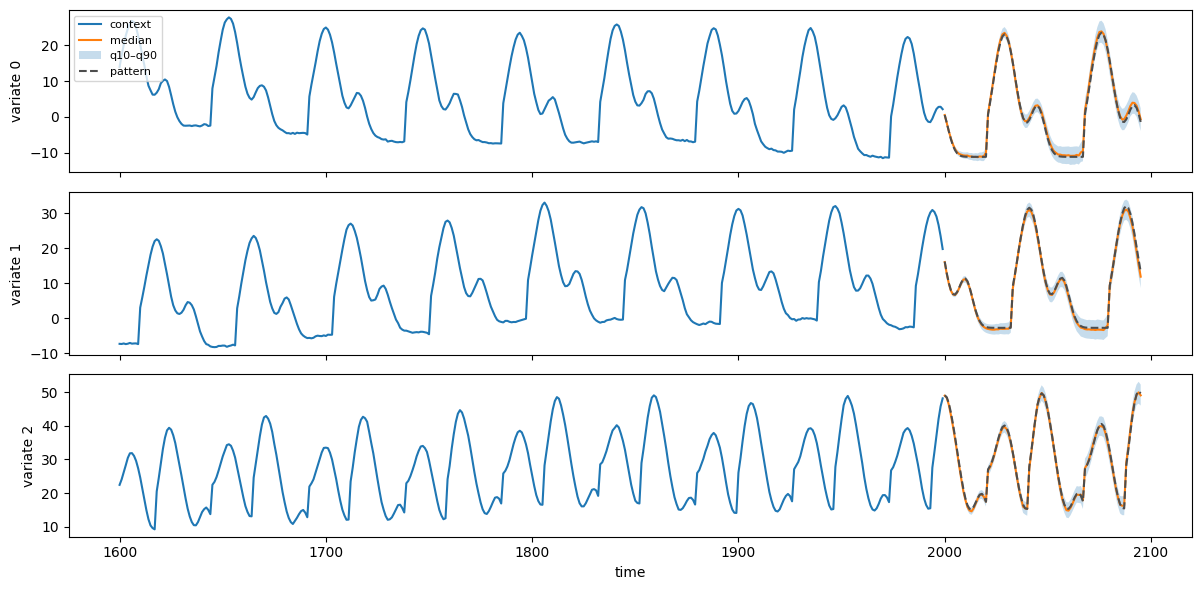

In [27]:
rng = np.random.default_rng(0)
horizon = 96
n = 2000
t = np.arange(n + horizon)

def pattern(t):
    # repeating double bump: a wide peak, then a narrow echo, growing over time
    phase = np.mod(t, 47)
    main = np.exp(-0.5 * ((phase - 8) / 5.5) ** 2)
    echo = 0.4 * np.exp(-0.5 * ((phase - 24) / 3.5) ** 2)
    return (14 + 0.01 * t) * (main + echo)

def lag(x, k):
    y = np.empty_like(x)
    y[:k] = x[0]
    y[k:] = x[:-k]
    return y

clean = np.stack([
    pattern(t),
    lag(pattern(t), 12),
    pattern(t) + pattern(t - 20),
])
walk = rng.standard_normal(clean.shape).cumsum(axis=-1)
series = clean + 0.2 * walk
context = series[None, :, :n]   # (1 series, 3 variates, 2000)

forecast = forecaster.forecast(context, prediction_length=horizon)
forecast.quantiles.shape        # (1, 3, 96, 21)

history = context[0]
median = forecast.median[0].detach().cpu().numpy()
low = forecast.quantile(0.1)[0].detach().cpu().numpy()
high = forecast.quantile(0.9)[0].detach().cpu().numpy()
true_future = clean[:, n:] + 0.2 * walk[:, n - 1:n]

tail = 400
t_hist = np.arange(n - tail, n)
t_fut = np.arange(n, n + horizon)

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t_hist, history[i, -tail:], label="context")
    ax.plot(t_fut, median[i], label="median")
    ax.fill_between(t_fut, low[i], high[i], alpha=0.25, label="q10–q90")
    ax.plot(t_fut, true_future[i], ls="--", color="0.3", label="pattern")
    ax.set_ylabel(f"variate {i}")
axes[0].legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("time")
fig.tight_layout()
plt.show()